# 02 — UCI model comparison: baseline CV, repeated nested CV and model selection

Logistic Regression, Random Forest and XGBoost are compared on the
**training portion only** (359 records). The locked test set from
notebook 01 is not used here.

| Setting | Mendeley pipeline (notebook 03) | This notebook |
|---|---|---|
| Groups | hash of six features | same |
| Models and defaults | LR (+StandardScaler), RF, XGBoost | same |
| Search spaces | see `uci_common.PARAMETER_SPACES` | same |
| Inner search | `RandomizedSearchCV`, `n_iter=10`, scored on high-risk recall | same |
| Repeated nested CV | 3 repeats (seeds 42–44) × 5 outer `StratifiedGroupKFold` × 3 inner (seed + 100) | same |
| Metrics | accuracy, macro F1, high-risk recall | same, **plus** macro precision, macro recall and per-class report |
| SMOTE | not used | not used |
| Selection rule | highest mean high-risk recall in repeated nested CV | same, with a macro-F1 tie-break made explicit |

Means ± standard deviations are over the 15 outer folds (3 repeats × 5
folds), with sample standard deviation (ddof = 1), as in the Mendeley summary.

In [1]:
import sys
from pathlib import Path

# Make ml_model/uci importable whether the notebook runs from
# ml_model/uci/notebooks (default) or from ml_model/uci.
UCI_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "uci_common.py").exists())
sys.path.insert(0, str(UCI_DIR))

import uci_common as uc

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("UCI folder:", UCI_DIR)

import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             make_scorer, precision_score, recall_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_predict, cross_validate)

uc.set_plot_style()
print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)

reports_dir = uc.REPORTS_DIR
reports_dir.mkdir(parents=True, exist_ok=True)

Python: 3.12.10
Interpreter: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\.venv\Scripts\python.exe
UCI folder: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci


scikit-learn: 1.9.1 | xgboost: 3.4.1


## 1. Load the training portion and verify the locked split

In [2]:
data = uc.load_train_test()
X, y, groups = data["X_train"], data["y_train"], data["groups_train"]

# The split must be identical to the one saved by notebook 01
saved = pd.read_csv(reports_dir / "locked_split_assignment.csv")
assert (saved.loc[saved["split"] == "train", "row_index"].to_numpy()
        == np.sort(data["train_idx"])).all()
assert (saved.loc[saved["split"] == "test", "row_index"].to_numpy()
        == np.sort(data["test_idx"])).all()

print("Training records:", len(X), "| groups:", len(np.unique(groups)))
print("Locked test records (not used here):", len(data["X_test"]))
print("Label mapping:", uc.LABEL_MAPPING)
print("Training class counts:",
      {uc.CLASS_NAMES[k]: int(v) for k, v in zip(*np.unique(y, return_counts=True))})

Training records: 359 | groups: 332
Locked test records (not used here): 92
Label mapping: {'high risk': 0, 'low risk': 1, 'mid risk': 2}
Training class counts: {'high risk': 89, 'low risk': 186, 'mid risk': 84}


## 2. Baseline: group-aware 5-fold CV with default hyperparameters

This mirrors Mendeley notebook 03, phases 1–4. It is a sanity check
before tuning and is **not** used for model selection.

In [3]:
models = uc.build_models()

baseline_cv = StratifiedGroupKFold(n_splits=5, shuffle=True,
                                   random_state=uc.RANDOM_STATE)

scoring = {
    "Accuracy": "accuracy",
    "Macro Precision": make_scorer(precision_score, average="macro", zero_division=0),
    "Macro Recall": make_scorer(recall_score, average="macro", zero_division=0),
    "Macro F1": "f1_macro",
    "High-Risk Recall": uc.HIGH_RISK_RECALL_SCORER,
}

baseline_rows = []
for name, model in models.items():
    scores = cross_validate(model, X, y, groups=groups, cv=baseline_cv,
                            scoring=scoring, n_jobs=1, error_score="raise")
    baseline_rows.append({"Model": name, **{
        m: uc.mean_std(scores[f"test_{m}"]) for m in uc.METRIC_COLUMNS}})

baseline_summary = pd.DataFrame(baseline_rows).set_index("Model")
display(baseline_summary)
baseline_summary.to_csv(reports_dir / "baseline_cv_summary.csv")

,Accuracy,Macro Precision,Macro Recall,Macro F1,High-Risk Recall
Model,,,,,
Logistic Regression,0.6601 ± 0.0379,0.5519 ± 0.1798,0.5443 ± 0.0452,0.5024 ± 0.0536,0.6510 ± 0.0766
Random Forest,0.7158 ± 0.0132,0.6805 ± 0.0343,0.6475 ± 0.0261,0.6431 ± 0.0370,0.8092 ± 0.0837
XGBoost,0.7046 ± 0.0351,0.6559 ± 0.0499,0.6296 ± 0.0381,0.6225 ± 0.0440,0.7980 ± 0.0622


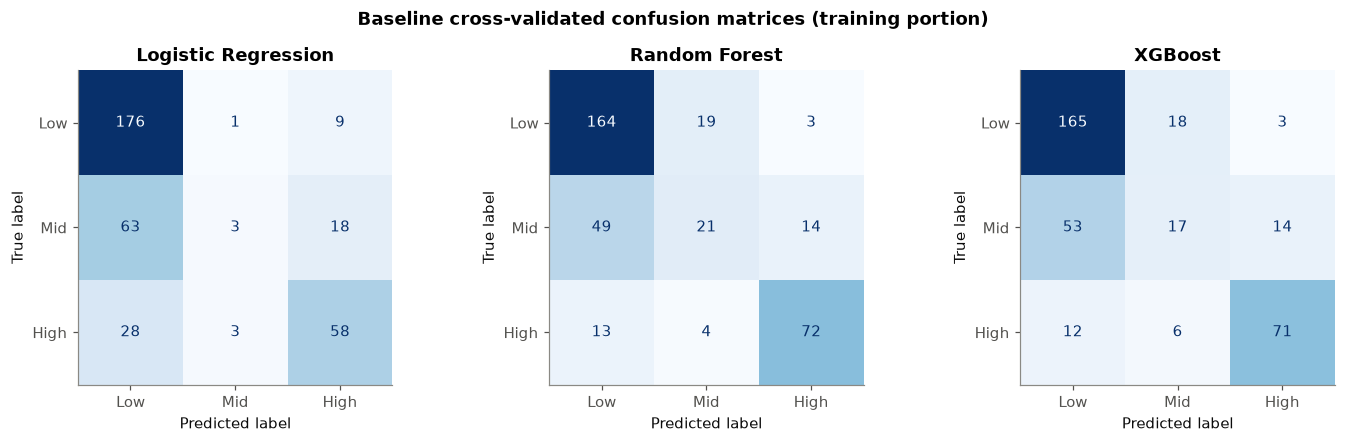

,High → Low,High → Mid,Total Missed High,Actual High
Model,,,,
Logistic Regression,28,3,31,89
Random Forest,13,4,17,89
XGBoost,12,6,18,89


In [4]:
codes = [uc.LABEL_MAPPING[c] for c in uc.CLINICAL_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
missed_rows = []

for ax, (name, model) in zip(axes, models.items()):
    preds = cross_val_predict(model, X, y, groups=groups, cv=baseline_cv, n_jobs=1)
    cm = confusion_matrix(y, preds, labels=codes)
    ConfusionMatrixDisplay(cm, display_labels=["Low", "Mid", "High"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.grid(False)
    ax.set_title(name)

    actual_high = y == uc.HIGH_RISK_CODE
    missed_rows.append({
        "Model": name,
        "High → Low": int((actual_high & (preds == uc.LABEL_MAPPING["low risk"])).sum()),
        "High → Mid": int((actual_high & (preds == uc.LABEL_MAPPING["mid risk"])).sum()),
        "Total Missed High": int((actual_high & (preds != uc.HIGH_RISK_CODE)).sum()),
        "Actual High": int(actual_high.sum()),
    })

fig.suptitle("Baseline cross-validated confusion matrices (training portion)",
             fontweight="bold")
fig.tight_layout()
fig.savefig(reports_dir / "baseline_cv_confusion_matrices.png", bbox_inches="tight")
plt.show()

missed_high = pd.DataFrame(missed_rows).set_index("Model")
display(missed_high)
missed_high.to_csv(reports_dir / "baseline_cv_missed_high_risk.csv")

### 2.1 Leakage check: why group-aware splitting matters

This is a diagnostic only. The same default models are scored with a
naive `StratifiedKFold` that ignores groups, so rows with identical
measurements but different labels can sit in both the training and
validation folds. The input has no exact duplicate rows left, so a
copy of a validation row can no longer be seen in training. On the
archived 732-row file, which still contained duplicates, the naive
split overstated Random Forest accuracy by 0.13. Here the differences
mainly reflect the two schemes' different fold partitions and can have
either sign.

In [5]:
from sklearn.model_selection import StratifiedKFold

naive_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=uc.RANDOM_STATE)
leak_rows = []
for name, model in models.items():
    naive = cross_validate(model, X, y, cv=naive_cv, scoring=scoring, n_jobs=1)
    grouped = cross_validate(model, X, y, groups=groups, cv=baseline_cv,
                             scoring=scoring, n_jobs=1)
    for metric in ["Accuracy", "Macro F1", "High-Risk Recall"]:
        a, b = naive[f"test_{metric}"].mean(), grouped[f"test_{metric}"].mean()
        leak_rows.append({"Model": name, "Metric": metric,
                          "Naive StratifiedKFold": a,
                          "Group-aware StratifiedGroupKFold": b,
                          "Optimism (naive - grouped)": a - b})

leakage_check = pd.DataFrame(leak_rows)
display(leakage_check.round(4))
leakage_check.to_csv(reports_dir / "leakage_check_naive_vs_grouped_cv.csv", index=False)

,Model,Metric,Naive StratifiedKFold,Group-aware StratifiedGroupKFold,Optimism (naive - grouped)
0,Logistic Regression,Accuracy,0.6602,0.6601,0.0001
1,Logistic Regression,Macro F1,0.5152,0.5024,0.0128
2,Logistic Regression,High-Risk Recall,0.6418,0.6510,-0.0092
3,Random Forest,Accuracy,0.6489,0.7158,-0.0670
4,Random Forest,Macro F1,0.5854,0.6431,-0.0577
5,Random Forest,High-Risk Recall,0.7516,0.8092,-0.0575
6,XGBoost,Accuracy,0.7018,0.7046,-0.0027
7,XGBoost,Macro F1,0.6328,0.6225,0.0103
8,XGBoost,High-Risk Recall,0.7523,0.7980,-0.0458


## 3. Repeated nested cross-validation

For each repeat (seeds 42, 43, 44):

* outer loop: `StratifiedGroupKFold(5, shuffle=True, random_state=seed)`
* inner loop: `StratifiedGroupKFold(3, shuffle=True, random_state=seed + 100)`
* `RandomizedSearchCV(n_iter=10, scoring=high-risk recall, random_state=seed)`
  is fitted on the outer-training part only, then scored on the
  outer-validation part

This gives 3 × 5 × 3 models = 45 outer evaluations. Group disjointness is
asserted at both levels.

In [6]:
fold_rows, per_class_rows = [], []
start = time.time()

for repeat, seed in enumerate(uc.REPEAT_SEEDS, start=1):
    outer_cv = StratifiedGroupKFold(n_splits=uc.OUTER_SPLITS, shuffle=True,
                                    random_state=seed)
    inner_cv = StratifiedGroupKFold(n_splits=uc.INNER_SPLITS, shuffle=True,
                                    random_state=seed + uc.INNER_SEED_OFFSET)

    for fold, (tr, val) in enumerate(outer_cv.split(X, y, groups), start=1):
        assert not set(groups[tr]) & set(groups[val])
        for inner_tr, inner_val in inner_cv.split(X.iloc[tr], y[tr], groups[tr]):
            assert not set(groups[tr][inner_tr]) & set(groups[tr][inner_val])

        for name, model in uc.build_models().items():
            search = RandomizedSearchCV(
                estimator=clone(model),
                param_distributions=uc.PARAMETER_SPACES[name],
                n_iter=uc.N_ITER,
                scoring=uc.HIGH_RISK_RECALL_SCORER,
                cv=inner_cv,
                random_state=seed,
                n_jobs=1,
                refit=True,
                error_score="raise",
            )
            search.fit(X.iloc[tr], y[tr], groups=groups[tr])
            pred = search.predict(X.iloc[val])

            fold_rows.append({
                "Model": name, "Repeat": repeat, "Fold": fold, "Seed": seed,
                "Validation Records": len(val),
                **uc.compute_metrics(y[val], pred),
                "Inner CV High-Risk Recall": search.best_score_,
                "Best Params": json.dumps(search.best_params_),
            })
            per_class_rows.append(
                uc.per_class_metrics(y[val], pred)
                  .assign(Model=name, Repeat=repeat, Fold=fold))

    print(f"Repeat {repeat} done ({time.time() - start:.0f} s elapsed)", flush=True)

nested_folds = pd.DataFrame(fold_rows)
nested_per_class = pd.concat(per_class_rows, ignore_index=True)[
    ["Model", "Repeat", "Fold", "Class", "Precision", "Recall", "F1", "Support"]]

nested_folds.to_csv(reports_dir / "repeated_nested_cv_folds.csv", index=False)
nested_per_class.to_csv(reports_dir / "repeated_nested_cv_per_class_folds.csv",
                        index=False)
print(f"Total time: {(time.time() - start) / 60:.1f} min")

Repeat 1 done (87 s elapsed)


Repeat 2 done (184 s elapsed)


Repeat 3 done (290 s elapsed)


Total time: 4.8 min


In [7]:
print("Total evaluations:", len(nested_folds))
print(nested_folds.groupby("Model").size())

assert len(nested_folds) == 45
assert (nested_folds.groupby("Model").size() == 15).all()
assert not nested_folds[uc.METRIC_COLUMNS].isna().any().any()
assert len(nested_per_class) == 45 * 3

print("\nAll 45 evaluations verified!")

Total evaluations: 45
Model
Logistic Regression    15
Random Forest          15
XGBoost                15
dtype: int64

All 45 evaluations verified!


### 3.1 Summary over the 15 outer folds

In [8]:
model_order = list(uc.build_models())

# Same layout as ml_model/reports/repeated_nested_cv_summary.csv
summary = (nested_folds.groupby("Model")[uc.METRIC_COLUMNS]
           .agg(["mean", "std"]).reindex(model_order).round(4))
summary.to_csv(reports_dir / "repeated_nested_cv_summary.csv")

summary_formatted = (nested_folds.groupby("Model")[uc.METRIC_COLUMNS]
                     .agg(uc.mean_std).reindex(model_order))
summary_formatted.to_csv(reports_dir / "repeated_nested_cv_summary_formatted.csv")
display(summary_formatted)

,Accuracy,Macro Precision,Macro Recall,Macro F1,High-Risk Recall
Model,,,,,
Logistic Regression,0.5961 ± 0.0542,0.5604 ± 0.0599,0.5523 ± 0.0378,0.5438 ± 0.0487,0.6632 ± 0.0834
Random Forest,0.6918 ± 0.0341,0.6656 ± 0.0618,0.6348 ± 0.0360,0.6220 ± 0.0380,0.8100 ± 0.1025
XGBoost,0.7288 ± 0.0365,0.7066 ± 0.0709,0.6566 ± 0.0464,0.6522 ± 0.0513,0.7915 ± 0.1032


In [9]:
# Per-class classification report, mean ± std over outer folds
per_class_summary = (
    nested_per_class
      .groupby(["Model", "Class"], sort=False)[["Precision", "Recall", "F1"]]
      .agg(uc.mean_std)
)
per_class_summary["Mean Support"] = (
    nested_per_class.groupby(["Model", "Class"], sort=False)["Support"].mean().round(1))
per_class_summary.to_csv(reports_dir / "repeated_nested_cv_per_class_summary.csv")
display(per_class_summary)

Precision           Recall  \
Model               Class                                         
Logistic Regression low risk   0.7418 ± 0.0846  0.7023 ± 0.1407   
                    mid risk   0.2563 ± 0.1072  0.2914 ± 0.1668   
                    high risk  0.6831 ± 0.1006  0.6632 ± 0.0834   
Random Forest       low risk   0.7511 ± 0.0733  0.8281 ± 0.1189   
                    mid risk   0.4662 ± 0.1881  0.2662 ± 0.1365   
                    high risk  0.7795 ± 0.0938  0.8100 ± 0.1025   
XGBoost             low risk   0.7476 ± 0.0595  0.9067 ± 0.0635   
                    mid risk   0.5541 ± 0.1863  0.2716 ± 0.1259   
                    high risk  0.8181 ± 0.0837  0.7915 ± 0.1032   

                                            F1  Mean Support  
Model               Class                                     
Logistic Regression low risk   0.7050 ± 0.0845          37.2  
                    mid risk   0.2617 ± 0.1215          16.8  
                    high risk  0.6645 ± 0.0494          17.8  
Random Forest       low risk   0.7777 ± 0.0312          37.2  
                    mid risk   0.3006 ± 0.1065          16.8  
                    high risk  0.7876 ± 0.0613          17.8  
XGBoost             low risk   0.8165 ± 0.0339          37.2  
                    mid risk   0.3413 ± 0.1225          16.8  
                    high risk  0.7987 ± 0.0630          17.8

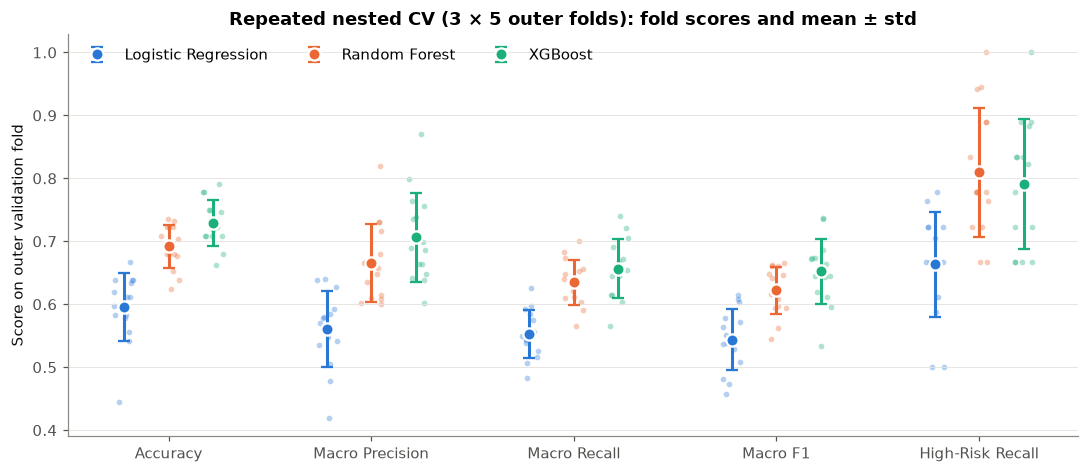

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.4))
offsets = {m: o for m, o in zip(model_order, (-0.22, 0, 0.22))}
rng = np.random.default_rng(0)  # jitter only

for name in model_order:
    sub = nested_folds[nested_folds["Model"] == name]
    for i, metric in enumerate(uc.METRIC_COLUMNS):
        vals = sub[metric].to_numpy()
        x = i + offsets[name]
        ax.scatter(x + rng.uniform(-0.05, 0.05, len(vals)), vals, s=14,
                   color=uc.MODEL_COLORS[name], alpha=0.35, linewidths=0)
        ax.errorbar(x, vals.mean(), yerr=vals.std(ddof=1), fmt="o", ms=8,
                    color=uc.MODEL_COLORS[name], mec="white", mew=1.5,
                    capsize=4, lw=2, label=name if i == 0 else None)

ax.set_xticks(range(len(uc.METRIC_COLUMNS)), uc.METRIC_COLUMNS)
ax.set_ylabel("Score on outer validation fold")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", frameon=False, ncol=3)
ax.set_title("Repeated nested CV (3 × 5 outer folds): fold scores and mean ± std")
fig.tight_layout()
fig.savefig(reports_dir / "repeated_nested_cv_metrics.png", bbox_inches="tight")
plt.show()

In [11]:
# How often each hyperparameter configuration was chosen by the inner search
param_frequency = (nested_folds.groupby(["Model", "Best Params"]).size()
                   .rename("Times Selected").reset_index()
                   .sort_values(["Model", "Times Selected"], ascending=[True, False]))
param_frequency.to_csv(reports_dir / "repeated_nested_cv_param_frequency.csv", index=False)
display(param_frequency.groupby("Model").head(3))

,Model,Best Params,Times Selected
0,Logistic Regression,"{""model__class_weight"": ""balanced"", ""model__C""...",6
1,Logistic Regression,"{""model__class_weight"": ""balanced"", ""model__C""...",5
2,Logistic Regression,"{""model__class_weight"": ""balanced"", ""model__C""...",3
14,Random Forest,"{""model__n_estimators"": 300, ""model__min_sampl...",3
10,Random Forest,"{""model__n_estimators"": 200, ""model__min_sampl...",2
13,Random Forest,"{""model__n_estimators"": 300, ""model__min_sampl...",2
15,XGBoost,"{""model__subsample"": 0.8, ""model__n_estimators...",1
16,XGBoost,"{""model__subsample"": 0.8, ""model__n_estimators...",1
17,XGBoost,"{""model__subsample"": 0.8, ""model__n_estimators...",1


## 4. Model selection

**Rule (same as Mendeley):** select the model with the highest mean
high-risk recall across the repeated nested CV outer folds. The Mendeley
pipeline did not need a tie-break. Here we make one explicit: if two
models tie on mean high-risk recall (to 4 decimal places), the higher
mean macro F1 wins.

Because every model is evaluated on the same 15 outer folds, we also
report the paired difference between the selected model and the
runner-up. This shows how decisive the choice is.

In [12]:
means = nested_folds.groupby("Model")[uc.METRIC_COLUMNS].mean()
ranking = (means.assign(**{"HRR (rounded)": means["High-Risk Recall"].round(4)})
                .sort_values(["HRR (rounded)", "Macro F1"], ascending=False)
                .drop(columns="HRR (rounded)"))
display(ranking.round(4))

selected_model = ranking.index[0]
runner_up = ranking.index[1]

wide = nested_folds.pivot_table(index=["Repeat", "Fold"], columns="Model",
                                values=["High-Risk Recall", "Macro F1"])
hrr_diff = wide["High-Risk Recall"][selected_model] - wide["High-Risk Recall"][runner_up]
f1_diff = wide["Macro F1"][selected_model] - wide["Macro F1"][runner_up]

print(f"Selected model: {selected_model}")
print(f"Runner-up: {runner_up}")
print(f"Paired high-risk recall difference: {hrr_diff.mean():+.4f} ± {hrr_diff.std(ddof=1):.4f}"
      f" (selected better in {(hrr_diff > 0).sum()}/15 folds, tied in {(hrr_diff == 0).sum()})")
print(f"Paired macro F1 difference: {f1_diff.mean():+.4f} ± {f1_diff.std(ddof=1):.4f}")

selection = {
    "selected_model": selected_model,
    "rule": ("Highest mean high-risk recall over the repeated nested CV outer "
             "folds (same rule as the Mendeley pipeline); ties at 4 decimals "
             "broken by mean macro F1."),
    "runner_up": runner_up,
    "paired_difference_vs_runner_up": {
        "high_risk_recall_mean": float(hrr_diff.mean()),
        "high_risk_recall_std": float(hrr_diff.std(ddof=1)),
        "folds_selected_better": int((hrr_diff > 0).sum()),
        "folds_tied": int((hrr_diff == 0).sum()),
        "macro_f1_mean": float(f1_diff.mean()),
    },
    "nested_cv_means": ranking.round(6).to_dict(orient="index"),
    "nested_cv_stds": nested_folds.groupby("Model")[uc.METRIC_COLUMNS]
                                  .std(ddof=1).round(6).to_dict(orient="index"),
    "outer_evaluations_per_model": 15,
}
with open(reports_dir / "model_selection.json", "w", encoding="utf-8") as f:
    json.dump(selection, f, indent=4)
print("\nSaved:", reports_dir / "model_selection.json")

,Accuracy,Macro Precision,Macro Recall,Macro F1,High-Risk Recall
Model,,,,,
Random Forest,0.6918,0.6656,0.6348,0.6220,0.8100
XGBoost,0.7288,0.7066,0.6566,0.6522,0.7915
Logistic Regression,0.5961,0.5604,0.5523,0.5438,0.6632


Selected model: Random Forest
Runner-up: XGBoost
Paired high-risk recall difference: +0.0185 ± 0.0547 (selected better in 6/15 folds, tied in 6)
Paired macro F1 difference: -0.0302 ± 0.0399

Saved: C:\Users\Andrei PC\Desktop\Maternal\ThesisPrototype-main-updated\ml_model\uci\reports\model_selection.json
